In [1]:
# Keep imports and data/output paths relative to the repository root.
import os
import sys
from pathlib import Path
from datetime import datetime
from uuid import uuid4

for repository_dir in (Path.cwd(), *Path.cwd().parents):
    if (repository_dir / ".geofm-root").is_file():
        os.chdir(repository_dir)
        break
else:
    raise FileNotFoundError("Open this notebook from inside the repository.")
if "src" not in sys.path:
    sys.path.insert(0, "src")

EXPERIMENT_NAME = "sen1floods11/croma/fcn_s1_own_preprocessing"
NOTEBOOK_PATH = "experiments/sen1floods11/croma/fcn_s1_own_preprocessing/01B_croma_on_sen1floods11_training_own_pre.ipynb"


#### **Imports**

In [2]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as FT
import torch.nn.functional as F
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import csv
import random
import json

from datetime import datetime
from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models.segmentation.fcn import FCNHead
from use_croma import PretrainedCROMA

In [3]:
'''
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
'''

'\nSEED = 42\n\nrandom.seed(SEED)\nnp.random.seed(SEED)\ntorch.manual_seed(SEED)\ntorch.cuda.manual_seed_all(SEED)\n'

#### **First things first**


In [4]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

pretrained_path = "pretrained/croma/CROMA_large.pt"

path_to_the_dataset = "datasets/sen1floods11/sen1floods11_hand_labeled_only/HandLabeled/"

path_to_the_dataset_index = "datasets/sen1floods11/sen1floods11_hand_labeled_only/flood_handlabeled/"

path_to_X = path_to_the_dataset + "S1Hand/"

path_to_Y = path_to_the_dataset + "LabelHand/"

path_to_train_csv = path_to_the_dataset_index + "flood_train_data.csv"

path_to_val_csv = path_to_the_dataset_index + "flood_valid_data.csv"

path_to_test_csv = path_to_the_dataset_index + "flood_test_data.csv"
path_to_test_bolivia_csv = path_to_the_dataset_index + "flood_bolivia_data.csv"

print(device)

cuda


In [5]:
CROP_SIZE = 120
IGNORE_INDEX = 255

#### **Functions**

In [6]:
def load_split_paths(csv_file, x_dir, y_dir):
    data = []

    with open(csv_file, newline="") as f:
        
        for x_name, y_name in csv.reader(f):
            x_path = Path(x_dir) / x_name.strip()
            y_path = Path(y_dir) / y_name.strip()
            
            if not x_path.is_file() or not y_path.is_file():
                print(f"Missing pair: {x_path}, {y_path}")
                continue

            data.append((x_path, y_path))

    return data

In [7]:
def load_image_pair(pair):
    x_path, y_path = pair

    with rasterio.open(x_path) as src:
        x = src.read().astype(np.float32)

    with rasterio.open(y_path) as src:
        y = src.read(1).astype(np.int16)

    # Original FCN preprocessing
    #x = np.nan_to_num(x)
    #x = np.clip(x, -50, 1)
    #x = (x + 50) / 51
    
    x = np.nan_to_num(x, nan=-50.0, posinf=0.0, neginf=0.0)
   
    # Original ignore-label convention
    y[y == -1] = 255

    return x, y

def prepare_sample(data):
    """
    Convert one sample to PyTorch tensors,
    retain raw SAR values and prepare its mask.

    Assumes data contains:
        image: [2, 512, 512]
        mask:  [1, 512, 512] or [512, 512]
    """

    image, mask = data

    image = torch.as_tensor(image, dtype=torch.float32)
    mask = torch.as_tensor(mask, dtype=torch.long).clone()

    if mask.ndim == 3:
        assert mask.shape[0] == 1
        mask = mask.squeeze(0)

    # Sen1Floods11 invalid pixels
    mask[mask == -1] = IGNORE_INDEX

    assert image.ndim == 3 and image.shape[0] == 2
    assert mask.shape == image.shape[-2:]
    assert torch.isfinite(image).all(), (
        "SAR image contains NaN or infinite values"
    )

    assert set(torch.unique(mask).tolist()).issubset(
        {0, 1, IGNORE_INDEX}
    ), "Unexpected mask values"

    # Normalize tile batches immediately before model inference.

    return image, mask

In [8]:
def preprocess_train(data):
    """
    Normalize the complete image,
    extract a random 120x120 crop,
    and apply synchronized random flips.
    """

    image, mask = prepare_sample(data)

    H, W = image.shape[-2:]

    assert H >= CROP_SIZE and W >= CROP_SIZE

    # Random crop coordinates
    top = torch.randint(
        0, H - CROP_SIZE + 1, (1,)
    ).item()

    left = torch.randint(
        0, W - CROP_SIZE + 1, (1,)
    ).item()

    # Same crop for image and ground-truth mask
    image = image[
        :, top:top + CROP_SIZE, left:left + CROP_SIZE
    ]

    mask = mask[
        top:top + CROP_SIZE, left:left + CROP_SIZE
    ]

    # Random horizontal flip
    if torch.rand(()) < 0.5:
        image = image.flip(-1)
        mask = mask.flip(-1)

    # Random vertical flip
    if torch.rand(()) < 0.5:
        image = image.flip(-2)
        mask = mask.flip(-2)

    return image, mask


## Note here mIoU is not being computed!
def preprocess_eval(data):
   
    return prepare_sample(data)

In [9]:
class Sen1Floods11Dataset(Dataset):
    def __init__(self, data_list, preprocess_func, crops_per_image=1):
        # Load each image only once into RAM
        self.loaded_data = [
            load_image_pair(pair) for pair in data_list
        ]

        self.preprocess_func = preprocess_func
        self.crops_per_image = crops_per_image

    def __len__(self):
        return len(self.loaded_data) * self.crops_per_image

    def __getitem__(self, idx):
        real_idx = idx % len(self.loaded_data)

        # This MUST generate a new random crop on every call
        return self.preprocess_func(self.loaded_data[real_idx])
    

class CROMAFloodSegmentation(nn.Module):
    def __init__(self, croma, head):
        super().__init__()
        
        self.croma = croma
        self.head = head
    
    def train(self, mode=True):
        super().train(mode)
        self.croma.eval()
        return self
    
    def forward(self, images):
        
        # 1. Extract pretrained CROMA features
        with torch.no_grad():
            outputs = self.croma(SAR_images=images)
            features = outputs["SAR_encodings"]
        
        # features: [B, 225, 1024]

        B, N, D = features.shape
        H = W = int(N ** 0.5)
        
        assert H * W == N
        
        # 2. Restore spatial structure
        spatial_features = features.transpose(1, 2).reshape(B, D, H, W)
        
        logits = self.head(spatial_features)
        # features: [B, 1024, 15, 15]
        
        # 4. Upsample to original image size
        logits = F.interpolate(
            logits,
            size=images.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # logits: [B, 2, 120, 120]

        return logits

#### Creating datasets

In [10]:
train_data = load_split_paths(path_to_train_csv, path_to_X, path_to_Y)
val_data = load_split_paths(path_to_val_csv, path_to_X, path_to_Y)

In [11]:
for split_name, pairs in [
    ("TRAIN", train_data),
    ("VALIDATION", val_data),
]:
    total_pixels = 0
    invalid_pixels = 0
    invalid_with_valid_labels = 0
    affected_images = 0

    for x_path, y_path in pairs:
        with rasterio.open(x_path) as src:
            x = src.read()
            bad = ~np.isfinite(x)

            # Also catch finite NoData values, if declared
            if src.nodata is not None:
                bad |= (x == src.nodata)

        with rasterio.open(y_path) as src:
            y = src.read(1)

        # A pixel is invalid if either SAR channel is invalid
        bad_pixel = bad.any(axis=0)

        total_pixels += bad_pixel.size
        invalid_pixels += bad_pixel.sum()
        affected_images += int(bad_pixel.any())

        valid_label = (y == 0) | (y == 1)
        invalid_with_valid_labels += (
            bad_pixel & valid_label
        ).sum()

    print(f"\n{split_name}")
    print("Affected images:", affected_images)
    print("Invalid SAR pixels:", invalid_pixels)
    print(
        "Invalid percentage:",
        f"{100 * invalid_pixels / total_pixels:.4f}%"
    )
    print(
        "Invalid SAR pixels with valid labels:",
        invalid_with_valid_labels
    )


TRAIN
Affected images: 23
Invalid SAR pixels: 1325136
Invalid percentage: 2.0059%
Invalid SAR pixels with valid labels: 24150

VALIDATION
Affected images: 9
Invalid SAR pixels: 219569
Invalid percentage: 0.9411%
Invalid SAR pixels with valid labels: 20571


In [12]:
channel_sum = np.zeros(2, dtype=np.float64)
channel_sq_sum = np.zeros(2, dtype=np.float64)
channel_count = np.zeros(2, dtype=np.int64)

for x_path, _ in train_data:
    with rasterio.open(x_path) as src:
        image = src.read().astype(np.float64)

    for c in range(2):
        values = image[c]
        values = values[np.isfinite(values)]

        channel_sum[c] += values.sum()
        channel_sq_sum[c] += np.square(values).sum()
        channel_count[c] += values.size

if (channel_count == 0).any():
    raise ValueError("Each SAR channel needs finite training pixels.")

mean = channel_sum / channel_count

std = np.sqrt(
    np.maximum(channel_sq_sum / channel_count - mean**2, 0)
)

print("VV mean/std:", mean[0], std[0])
print("VH mean/std:", mean[1], std[1])

if not np.isfinite(mean).all() or not np.isfinite(std).all() or not (std > 0).all():
    raise ValueError("Invalid training normalization statistics.")


VV mean/std: -10.392862128651208 4.038801279754007
VH mean/std: -17.24110241935538 4.75397103524207


In [13]:
def normalize_croma_fixed(images):
    # images: [B, 2, H, W]
    images = images.float()

    mu = torch.as_tensor(
        mean, dtype=images.dtype, device=images.device
    ).view(1, 2, 1, 1)

    sigma = torch.as_tensor(
        std, dtype=images.dtype, device=images.device
    ).view(1, 2, 1, 1)

    images = (images - (mu - 2 * sigma)) / (
        4 * sigma
    ).clamp_min(1e-6)

    return images.clamp(0.0, 1.0)

preprocessing = {
    "method": "fixed_training_mean_std",
    "quantize_uint8": False,
    "channel_order": ["VV", "VH"],
    "nonfinite_fill": {"nan": -50.0, "posinf": 0.0, "neginf": 0.0},
    "mean": mean.tolist(),
    "std": std.tolist(),
}


In [14]:
print(f"Train samples: {len(train_data)}")
print(f"Validation samples: {len(val_data)}")

Train samples: 252
Validation samples: 89


In [15]:
print(train_data[0])

(WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/S1Hand/Ghana_103272_S1Hand.tif'), WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Ghana_103272_LabelHand.tif'))


In [16]:
train_dataset = Sen1Floods11Dataset(
    data_list=train_data,
    preprocess_func=preprocess_train,
    crops_per_image=1
)

valid_dataset = Sen1Floods11Dataset(
    data_list=val_data,
    preprocess_func=preprocess_eval,
    crops_per_image=1
)

#### Creating DataLoaders

In [17]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Training batch checks

images, masks = next(iter(train_loader))

print("Training images:", images.shape)
print("Training masks:", masks.shape)

print("Image min:", images.min().item())
print("Image max:", images.max().item())

print("Water pixels:", (masks == 1).sum().item())
print("Non-water pixels:", (masks == 0).sum().item())
print("Ignored pixels:", (masks == IGNORE_INDEX).sum().item())

assert torch.isfinite(images).all()

assert set(torch.unique(masks).tolist()).issubset(
    {0, 1, IGNORE_INDEX}
)

# Validation batch checks

val_images, val_masks = next(iter(valid_loader))

print("-" * 40)
print("Validation images:", val_images.shape)
print("Validation masks:", val_masks.shape)

Training images: torch.Size([16, 2, 120, 120])
Training masks: torch.Size([16, 120, 120])
Image min: -50.0
Image max: 14.502362251281738
Water pixels: 7388
Non-water pixels: 207612
Ignored pixels: 15400
----------------------------------------
Validation images: torch.Size([1, 2, 512, 512])
Validation masks: torch.Size([1, 512, 512])


##### Loading CROMA

In [18]:
croma = PretrainedCROMA(pretrained_path= pretrained_path, 
                        size='large', 
                        modality='SAR', 
                        image_resolution=120)

croma = croma.to(device)

Initializing SAR encoder


In [19]:
croma.requires_grad_(False) # Freeze the weights of CROMA
croma.eval()

PretrainedCROMA(
  (s1_encoder): ViT(
    (linear_input): Linear(in_features=128, out_features=1024, bias=True)
    (transformer): BaseTransformer(
      (layers): ModuleList(
        (0-11): 12 x ModuleList(
          (0): Attention(
            (to_qkv): Linear(in_features=1024, out_features=3072, bias=False)
            (to_out): Linear(in_features=1024, out_features=1024, bias=True)
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
          (1): FFN(
            (net): Sequential(
              (0): Linear(in_features=1024, out_features=4096, bias=True)
              (1): GELU(approximate='none')
              (2): Dropout(p=0.0, inplace=False)
              (3): Linear(in_features=4096, out_features=1024, bias=True)
            )
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
          )
        )
      )
      (norm_out): LayerNo

### Creating the head

In [20]:
head = FCNHead(in_channels=1024, channels=2)

head[1] = nn.GroupNorm(
    num_groups=16,
    num_channels=256
)

head = head.to(device)

In [21]:
model = CROMAFloodSegmentation(croma, head).to(device)

In [22]:
LR = 5e-4

class_weights = torch.tensor(
    [1.0, 8.0],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=IGNORE_INDEX
)

optimizer = torch.optim.AdamW(
    model.head.parameters(),
    lr=LR,
    weight_decay=1e-2
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=len(train_loader) * 10,
    T_mult=2,
    eta_min=0
)

In [23]:
def train_one_epoch(model, train_loader, optimizer, criterion, device):

    model.train()

    total_loss = 0.0
    total_weight = 0

    for images, masks in train_loader:

        # Move batch to GPU
        images = images.to(device)
        masks = masks.to(device)
        
        images = normalize_croma_fixed(images)
        
        valid = masks != IGNORE_INDEX

        if not valid.any():
            continue

        # Reset previous gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        logits = model(images)

        # Compute segmentation loss
        loss = criterion(logits, masks)

        # Backpropagation
        loss.backward()

        # Update FCN head weights
        optimizer.step()
        
        # Scheduler step
        scheduler.step()
        
        # Correct denominator of the weighted mean
        batch_weight = criterion.weight[masks[valid]].sum().item()

        total_loss += loss.item() * batch_weight
        total_weight += batch_weight

    if total_weight == 0:
        raise RuntimeError("No valid training pixels.")

    return total_loss / total_weight

In [24]:
@torch.inference_mode()
def sliding_window_logits(
    model,
    image,
    device,
    tile_size=120,
    stride=60,
    tile_batch_size=8
):
    """
    Predict segmentation logits for one complete image.

    Parameters
    ----------
    model:
        Frozen CROMA + trained FCN head.

    image:
        Tensor [2, H, W], raw SAR values with nonfinite pixels replaced.

    device:
        CUDA or CPU.

    tile_size:
        Spatial size of each CROMA input (120).

    stride:
        Distance between consecutive windows (60 = 50% overlap).

    tile_batch_size:
        Number of windows processed simultaneously.

    Returns
    -------
    logits:
        Tensor [2, H, W] on CPU.
    """

    model.eval()

    C, H, W = image.shape

    assert C == 2
    assert H >= tile_size and W >= tile_size
    assert 0 < stride <= tile_size

    # Generate starting positions along one dimension
    def get_starts(length):
        starts = list(
            range(0, length - tile_size + 1, stride)
        )

        # Ensure the final window reaches the image boundary
        if starts[-1] != length - tile_size:
            starts.append(length - tile_size)

        return starts

    # All window coordinates
    positions = [
        (top, left)
        for top in get_starts(H)
        for left in get_starts(W)
    ]

    # Accumulate predictions and coverage counts
    logits_sum = torch.zeros((2, H, W), dtype=torch.float32)
    counts = torch.zeros((H, W), dtype=torch.float32)

    # Process windows in batches
    for start in range(0, len(positions), tile_batch_size):

        batch_positions = positions[start:start + tile_batch_size]

        # Extract tiles
        tiles = torch.stack([
            image[:, top:top + tile_size, left:left + tile_size]
            for top, left in batch_positions
        ])

        tiles = tiles.to(device)
        tiles = normalize_croma_fixed(tiles)

        # Run frozen CROMA + FCN head
        outputs = model(tiles).cpu()

        # Place tile predictions back into the full image
        for (top, left), logits in zip(batch_positions, outputs):

            logits_sum[
                :, top:top + tile_size, left:left + tile_size
            ] += logits

            counts[
                top:top + tile_size, left:left + tile_size
            ] += 1

    assert (counts > 0).all(), "Some pixels were not covered."

    # Average logits wherever windows overlap
    return logits_sum / counts.unsqueeze(0)


import torch.nn.functional as F

@torch.inference_mode()
def validate(model, valid_loader, criterion, device):

    model.eval()

    total_loss = 0.0
    total_valid_pixels = 0

    TP = FP = FN = TN = 0

    for images, masks in valid_loader:

        # Process every complete image in the batch.
        for image, mask in zip(images, masks):
            mask = mask.cpu()
            
            
            valid = mask != IGNORE_INDEX

            if not valid.any():
                continue

            # Reconstruct logits using overlapping windows.
            logits = sliding_window_logits(
                model,
                image,
                device,
                tile_size=CROP_SIZE,
                stride=CROP_SIZE // 2,
                tile_batch_size=8
            )
            
            logits_device = logits.unsqueeze(0).to(device)
            mask_device = mask.unsqueeze(0).to(device=device, dtype=torch.long)

            loss = criterion(logits_device, mask_device)

            image_weight = criterion.weight[
                mask_device[mask_device != IGNORE_INDEX]
            ].sum().item()

            total_loss += loss.item() * image_weight
            total_valid_pixels += image_weight

            prediction = logits.argmax(dim=0)

            TP += ((prediction == 1) & (mask == 1) & valid).sum().item()
            FP += ((prediction == 1) & (mask == 0) & valid).sum().item()
            FN += ((prediction == 0) & (mask == 1) & valid).sum().item()
            TN += ((prediction == 0) & (mask == 0) & valid).sum().item()

    if total_valid_pixels == 0:
        raise RuntimeError("No valid validation pixels.")

    val_loss = total_loss / total_valid_pixels

    water_iou = TP / (TP + FP + FN) if TP + FP + FN else float("nan")
    nonwater_iou = TN / (TN + FP + FN) if TN + FP + FN else float("nan")
    miou = (water_iou + nonwater_iou) / 2

    return {
        "val_loss": val_loss,
        "water_iou": water_iou,
        "miou": miou
    }

In [25]:
metrics = validate(model, valid_loader, criterion, device)

print(f"Validation Loss:      {metrics['val_loss']:.4f}")
print(f"Validation Water IoU: {metrics['water_iou']:.4f}")
print(f"Validation mIoU:      {metrics['miou']:.4f}")

Validation Loss:      0.7716
Validation Water IoU: 0.1104
Validation mIoU:      0.0561


In [26]:
EPOCHS = 100
best_val_iou = -1.0
best_epoch = None


# A new directory is created each time this run cell is executed.
run_id = datetime.now().astimezone().strftime("%Y-%m-%d_%H-%M-%S_%f") + "_" + uuid4().hex[:8]
model_name = f"croma_own_preprocessing_float_{run_id}"
checkpoint_dir = Path("runs") / EXPERIMENT_NAME / f"train_{model_name}"
checkpoint_dir.mkdir(parents=True, exist_ok=False)
print(f"Run directory: {checkpoint_dir}")
checkpoint_path = checkpoint_dir / f"{model_name}.pt"
history_path = checkpoint_dir / f"{model_name}_training_history.json"
print(f"Checkpoint path for testing: {checkpoint_path.as_posix()}")

with (checkpoint_dir / "run.json").open("w", encoding="utf-8") as run_file:
    json.dump({
        "experiment": EXPERIMENT_NAME,
        "model_name": checkpoint_path.stem,
        "phase": "train",
        "run_id": run_id,
        "started_at": datetime.now().astimezone().isoformat(),
        "notebook": NOTEBOOK_PATH,
        "pretrained_weights": pretrained_path,
        "preprocessing": preprocessing,
    "checkpoint": checkpoint_path.as_posix(),
    "history": history_path.as_posix(),
    }, run_file, indent=4)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_water_iou": [],
    "val_miou": []
}

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model=model,
        criterion=criterion,
        train_loader=train_loader,
        device=device,
        optimizer=optimizer
    )
    
    metrics = validate(
        model=model,
        valid_loader=valid_loader,
        criterion=criterion,
        device=device
    )

    val_loss = metrics["val_loss"]
    val_water_iou = metrics["water_iou"]
    val_miou = metrics["miou"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_water_iou"].append(val_water_iou)
    history["val_miou"].append(val_miou)

  
    if val_water_iou > best_val_iou:

        best_val_iou = val_water_iou
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "head_state_dict": model.head.state_dict(),
                "preprocessing": preprocessing,
                "best_val_water_iou": best_val_iou,
                "val_miou": val_miou,
                "val_loss": val_loss,
            },
            checkpoint_path
        )
    
    with open(history_path, "w") as f:
        json.dump({
            "run_id": run_id,
            "epochs_completed": epoch + 1,
            "best_epoch": best_epoch,
            "best_val_water_iou": best_val_iou,
            "history": history
        }, f, indent=4)

 
    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Water IoU: {val_water_iou:.4f} | "
        f"mIoU: {val_miou:.4f}"
    )

print(
    f"\nBest model: Epoch {best_epoch}, "
    f"Water IoU = {best_val_iou:.4f}"
)

Run directory: runs\croma_sen1floods11\own_preprocessing\train_croma_own_preprocessing_float_2026-10-20_16-05-26_695085_48942d00
Checkpoint path for testing: runs/croma_sen1floods11/own_preprocessing/train_croma_own_preprocessing_float_2026-10-20_16-05-26_695085_48942d00/croma_own_preprocessing_float_2026-10-20_16-05-26_695085_48942d00.pt
Epoch [01/100] | Train Loss: 0.7987 | Val Loss: 0.4058 | Water IoU: 0.5168 | mIoU: 0.7111
Epoch [02/100] | Train Loss: 0.4025 | Val Loss: 0.3388 | Water IoU: 0.4595 | mIoU: 0.6653
Epoch [03/100] | Train Loss: 0.3581 | Val Loss: 0.2950 | Water IoU: 0.5135 | mIoU: 0.7072
Epoch [04/100] | Train Loss: 0.3585 | Val Loss: 0.2779 | Water IoU: 0.4800 | mIoU: 0.6807
Epoch [05/100] | Train Loss: 0.3255 | Val Loss: 0.2664 | Water IoU: 0.4761 | mIoU: 0.6772
Epoch [06/100] | Train Loss: 0.2901 | Val Loss: 0.2629 | Water IoU: 0.5236 | mIoU: 0.7138
Epoch [07/100] | Train Loss: 0.2847 | Val Loss: 0.2584 | Water IoU: 0.5192 | mIoU: 0.7103
Epoch [08/100] | Train Loss: 

In [27]:
print(
    "CROMA trainable parameters:",
    sum(p.numel() for p in model.croma.parameters()
        if p.requires_grad)
)

print(
    "Head trainable parameters:",
    sum(p.numel() for p in model.head.parameters()
        if p.requires_grad)
)

CROMA trainable parameters: 0
Head trainable parameters: 2360322


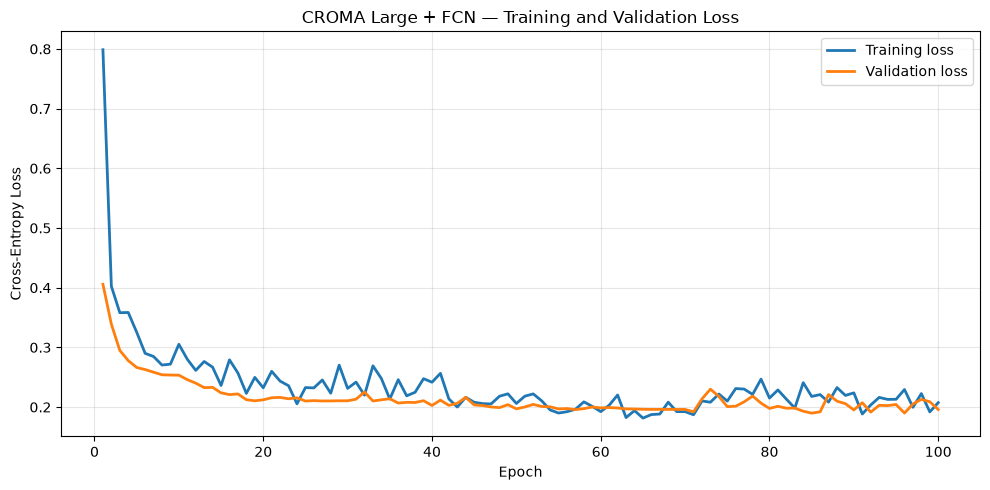

In [28]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Training loss",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("CROMA Large + FCN — Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(checkpoint_dir / "training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

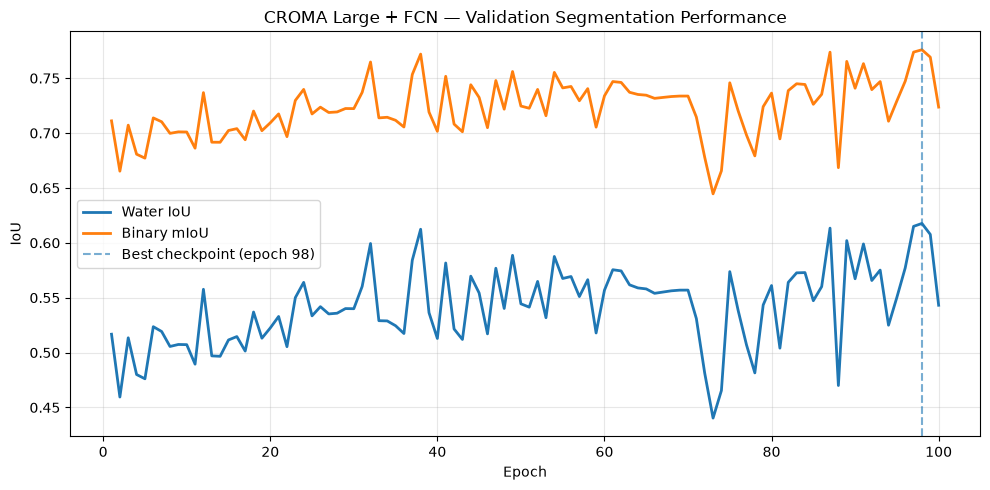

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["val_water_iou"],
    label="Water IoU",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_miou"],
    label="Binary mIoU",
    linewidth=2
)

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best checkpoint (epoch {best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("CROMA Large + FCN — Validation Segmentation Performance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(checkpoint_dir / "validation_iou.png", dpi=150, bbox_inches="tight")
plt.show()